# 04 · Red neuronal en Keras (Módulo 4)
**Sistema de apoyo para detección de tumores cerebrales en resonancia magnética**

**Modelo:** MobileNetV2 preentrenada (ImageNet) + una cabeza densa con dropout y dos salidas:
- `tumor`: probabilidad de que haya tumor (sigmoide). Es la salida principal.
- `tipo`: tipo de tumor más probable (glioma, meningioma o pituitary). Es un dato secundario y solo se entrena con los casos de tumor.

**Plan de este notebook**
1. **Validación cruzada de 5 pliegues** de la **cabeza** sobre los rasgos guardados (mismos pliegues y mismas métricas que los modelos clásicos).
2. **Modelo final:** se aparta cerca de 15 % del entrenamiento como validación (por grupos de similitud), se entrena la cabeza y después se hace **ajuste fino** de las últimas capas de MobileNetV2 con tasa baja, **una sola vez**.
3. Historial por época, curvas con la mejor época marcada y diagnóstico automático de convergencia.
4. Umbral para sensibilidad objetivo 0.98, elegido sin usar la prueba (con las predicciones fuera de pliegue si se exporta la cabeza; con la validación apartada si se exporta el ajuste fino).
5. Evaluación **única** en el conjunto de prueba.
6. Tabla comparativa de los 5 modelos, prueba de McNemar e intervalos de Wilson.
7. Galería Grad-CAM: la **zona que más influyó**.
8. Exportación del modelo `v001` para la aplicación.

**Aclaración importante (decisión del usuario, por tiempo de cómputo en CPU):** la validación cruzada de la red se hizo sobre **la cabeza con los rasgos de MobileNetV2 congelados**. El ajuste fino se entrenó **una sola vez** con una validación apartada; no tiene 5 pliegues. Así se reporta en todas las tablas.

**Qué pérdida se vigila:** todos los callbacks (`EarlyStopping`, `ReduceLROnPlateau`, `ModelCheckpoint`) vigilan `val_loss`, la **pérdida total de validación** = pérdida de `tumor` (ponderada por clase) + 0.5 × pérdida de `tipo`.

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import json
import shutil
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image as Imagen, Markdown, display


from app.backend.ml import config, entrenar, inferencia, rasgos, red
from app.backend.ml.diagnostico import diagnosticar, graficar_curvas
from app.backend.ml.gradcam import mapa_gradcam, superponer
from app.backend.ml.metricas import elegir_umbral, mcnemar, metricas_binarias, metricas_por_pliegue, wilson
from app.backend.ml.preprocesar import cargar_lote, leer_imagen

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
VERSION = "v001"
CARPETA_VERSION = config.MODELOS / VERSION
CARPETA_VERSION.mkdir(parents=True, exist_ok=True)
NOMBRE_RED = "Red Keras (MobileNetV2)"
OBJETIVO = config.SENSIBILIDAD_OBJETIVO

# Hiperparámetros (fijos; no se ajustaron con la prueba)
EPOCAS_CABEZA, PACIENCIA_CABEZA, TASA_CABEZA, LOTE_CABEZA = 60, 8, 1e-3, 64
EPOCAS_AJUSTE, PACIENCIA_AJUSTE, TASA_AJUSTE, LOTE_AJUSTE, CAPAS_AJUSTE = 8, 3, 1e-5, 32, 30
FRACCION_VALIDACION = 0.15
INICIO = time.time()
tiempos = {}
print("Versiones:", config.versiones())

Versiones: {'python': '3.12.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'opencv': '5.1.0', 'pandas': '3.1.1'}


## 1. Datos

In [2]:
man = pd.read_csv(config.MANIFIESTO)
FIRMA = rasgos.firma_cache(man)
with np.load(config.RASGOS / "rasgos_mobilenet.npz", allow_pickle=False) as d:
    X_todo, rutas_x = d["X"], d["rutas"]
    assert str(d["firma"]) == FIRMA, "Los rasgos guardados son de otro manifiesto o preprocesamiento: ejecute de nuevo el notebook 02."
assert (rutas_x == man.ruta.to_numpy()).all(), "Los rasgos no corresponden al manifiesto: ejecute de nuevo el notebook 02."

ruta_imagenes = config.RASGOS / "imagenes_160.npy"
ruta_firma = config.RASGOS / "imagenes_160.firma.txt"
if ruta_imagenes.exists() and ruta_firma.exists() and ruta_firma.read_text(encoding="utf-8").strip() == FIRMA:
    imagenes = np.load(ruta_imagenes)
else:
    imagenes = cargar_lote([config.RAIZ / r for r in man.ruta], hilos=12)
print("Imágenes preparadas en memoria:", imagenes.shape, imagenes.dtype, f"{imagenes.nbytes / 1e6:.0f} MB")

ent = (man.particion == "entrenamiento").to_numpy()
pru = (man.particion == "prueba").to_numpy()
man_ent, man_pru = man[ent].reset_index(drop=True), man[pru].reset_index(drop=True)
X_ent, img_ent, img_pru = X_todo[ent], imagenes[ent], imagenes[pru]
y_ent, tipo_ent = entrenar.etiquetas_de_clases(man_ent.clase)
y_pru, tipo_pru = entrenar.etiquetas_de_clases(man_pru.clase)
MAYORITARIA = float(max(y_ent.mean(), 1 - y_ent.mean()))
print(f"Entrenamiento: {len(y_ent):,} · Prueba: {len(y_pru):,} · clase mayoritaria (tumor): {MAYORITARIA:.1%}")
print("Pesos de clase:", {k: round(v, 4) for k, v in red.pesos_clase(y_ent).items()})

Imágenes preparadas en memoria: (3600, 160, 160, 3) uint8 276 MB
Entrenamiento: 2,880 · Prueba: 720 · clase mayoritaria (tumor): 89.8%
Pesos de clase: {1: 0.5568, 0: 4.898}


## 2. Arquitectura

In [3]:
red.construir_cabeza().summary()
_completo = red.construir_completo()
print(f"\nModelo completo: {len(_completo.layers)} capas · {_completo.count_params():,} parámetros")
print("Entrada:", _completo.input.shape, "· salidas:", {k: v.shape for k, v in _completo.output.items()})
print("Capa para Grad-CAM:", red.NOMBRE_CAPA_GRADCAM, _completo.get_layer(red.NOMBRE_CAPA_GRADCAM).output.shape)
del _completo

Model: "cabeza"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rasgos (InputLayer) │ (None, 1280)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densa (Dense)       │ (None, 256)       │    327,936 │ rasgos[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ densa[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tumor_logit (Dense) │ (None, 1)         │        257 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tipo (Dense)        │ (None, 3)         │        771 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tumor (Activation)  │ (None, 1)         │          0 │ tumor_logit[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 328,964 (1.25 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 0 (0.00 B)


Modelo completo: 161 capas · 2,586,948 parámetros
Entrada: (None, 160, 160, 3) · salidas: {'tumor': (None, 1), 'tipo': (None, 3)}
Capa para Grad-CAM: out_relu (None, 5, 5, 1280)


## 3. Validación cruzada de la cabeza (5 pliegues)
Mismos pliegues que el notebook 03 (por grupos de similitud, columna `pliegue` del manifiesto). En cada pliegue, del bloque de entrenamiento se aparta una parte (1 de 7, por grupos) para la detención temprana; el bloque fuera de pliegue no participa en el entrenamiento ni en la detención: solo recibe predicciones.

In [4]:
t0 = time.time()
GRUPOS_ENT = man_ent.grupo_similitud.to_numpy()
assert not set(GRUPOS_ENT) & set(man_pru.grupo_similitud), "Hay grupos de similitud repartidos entre entrenamiento y prueba."
cv = entrenar.kfold_cabeza(X_ent, y_ent, tipo_ent, estratos=man_ent.clase.to_numpy(), grupos=GRUPOS_ENT, n_pliegues=config.N_PLIEGUES,
                           fraccion_val=FRACCION_VALIDACION, epocas_max=EPOCAS_CABEZA, tasa=TASA_CABEZA,
                           lote=LOTE_CABEZA, paciencia=PACIENCIA_CABEZA, semilla=config.SEMILLA)
tiempos["kfold_cabeza_s"] = time.time() - t0
prob_oof, pliegue_de = cv["prob_oof"], cv["pliegue_oof"]
assert not np.isnan(prob_oof).any()

# Comprobación: son exactamente los pliegues del notebook 03
oof_previas = pd.read_csv(config.RESULTADOS / "predicciones_oof.csv")
oof_previas = oof_previas[oof_previas.modelo != NOMBRE_RED]
referencia = oof_previas[oof_previas.modelo == oof_previas.modelo.iloc[0]].set_index("ruta").loc[man_ent.ruta, "pliegue"].to_numpy()
assert (referencia == pliegue_de).all() and (man_ent.pliegue.to_numpy() == pliegue_de).all(), "Los pliegues no coinciden con los del notebook 03 y el manifiesto."
print(f"Pliegues idénticos a los del notebook 03. Validación cruzada en {tiempos['kfold_cabeza_s']:.0f} s")

umbral_cv = elegir_umbral(y_ent, prob_oof, OBJETIVO)
METRICAS = ["sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud"]
por_pliegue = pd.DataFrame(metricas_por_pliegue(y_ent, prob_oof, pliegue_de, umbral_cv))
en_05 = pd.DataFrame(cv["pliegues"])
por_pliegue["sensibilidad_umbral_05"], por_pliegue["especificidad_umbral_05"] = en_05.sensibilidad, en_05.especificidad
por_pliegue.insert(0, "modelo", NOMBRE_RED)
display(por_pliegue.round(4))
display(en_05[["pliegue", "mejor_epoca", "epocas", "exactitud_tipo"]].round(4))

NOTA_RED = "K-fold sobre la cabeza con rasgos congelados; el ajuste fino se entrenó una sola vez"
total = metricas_binarias(y_ent, prob_oof, umbral_cv)
fila_cv = {"modelo": NOMBRE_RED, "umbral": umbral_cv}
for met in METRICAS:
    fila_cv[f"{met}_media"], fila_cv[f"{met}_std"] = por_pliegue[met].mean(), por_pliegue[met].std(ddof=1)
fila_cv.update({"sensibilidad_oof": total["sensibilidad"], "especificidad_oof": total["especificidad"], "auc_oof": total["auc"],
                "vp": total["vp"], "vn": total["vn"], "fp": total["fp"], "fn": total["fn"],
                "segundos_cv": tiempos["kfold_cabeza_s"], "nota": NOTA_RED})


def agregar(archivo, nuevas):
    """Añade las filas de la red al CSV (quita antes las de una corrida anterior de este notebook)."""
    ruta = config.RESULTADOS / archivo
    previas = pd.read_csv(ruta)
    previas = previas[previas.modelo != NOMBRE_RED]
    junto = pd.concat([previas, nuevas], ignore_index=True)
    junto.to_csv(ruta, index=False, encoding="utf-8")
    return junto


cv_pliegues = agregar("cv_pliegues.csv", por_pliegue)
cv_resumen = agregar("cv_resumen.csv", pd.DataFrame([fila_cv]))
agregar("predicciones_oof.csv", pd.DataFrame({
    "ruta": man_ent.ruta, "modelo": NOMBRE_RED, "pliegue": pliegue_de, "clase": man_ent.clase, "es_tumor": y_ent,
    "probabilidad_tumor": prob_oof, "umbral": umbral_cv, "prediccion": (prob_oof >= umbral_cv).astype(int)}))
print(f"Cabeza en validación cruzada · umbral {umbral_cv:.4f} · "
      + " · ".join(f"{m} {fila_cv[m + '_media']:.4f} ± {fila_cv[m + '_std']:.4f}" for m in METRICAS[:5]))
print(f"Exactitud del tipo de tumor (solo casos de tumor), media de pliegues: {en_05.exactitud_tipo.mean():.4f}")

Pliegues idénticos a los del notebook 03. Validación cruzada en 29 s


,modelo,pliegue,umbral,vp,vn,fp,fn,sensibilidad,especificidad,precision,f1,exactitud,auc,sensibilidad_umbral_05,especificidad_umbral_05
0,Red Keras (MobileNetV2),1,0.5205,511,53,6,6,0.9884,0.8983,0.9884,0.9884,0.9792,0.9802,0.9884,0.8983
1,Red Keras (MobileNetV2),2,0.5205,504,51,8,13,0.9749,0.8644,0.9844,0.9796,0.9635,0.9759,0.9749,0.8475
2,Red Keras (MobileNetV2),3,0.5205,506,53,5,12,0.9768,0.9138,0.9902,0.9835,0.9705,0.9871,0.9768,0.9138
3,Red Keras (MobileNetV2),4,0.5205,503,56,3,14,0.9729,0.9492,0.9941,0.9834,0.9705,0.9922,0.9749,0.9492
4,Red Keras (MobileNetV2),5,0.5205,511,53,6,6,0.9884,0.8983,0.9884,0.9884,0.9792,0.9925,0.9884,0.8983


,pliegue,mejor_epoca,epocas,exactitud_tipo
0,1,17,25,0.8897
1,2,5,13,0.8491
2,3,8,16,0.8668
3,4,5,13,0.8839
4,5,4,12,0.8569


Cabeza en validación cruzada · umbral 0.5205 · sensibilidad 0.9803 ± 0.0075 · especificidad 0.9048 ± 0.0307 · precision 0.9891 ± 0.0035 · f1 0.9846 ± 0.0038 · auc 0.9856 ± 0.0074
Exactitud del tipo de tumor (solo casos de tumor), media de pliegues: 0.8693


## 4. Modelo final
### 4.1 Validación apartada y entrenamiento de la cabeza
Se aparta una de 7 partes del entrenamiento (cerca de 15 %; estratificada por las 4 clases, **por grupos de similitud**, semilla 42) como validación. Ningún grupo queda repartido entre esa validación y su entrenamiento. La prueba sigue sin tocarse.

In [5]:
indices = np.arange(len(man_ent))
i_tr, i_va = entrenar.apartar_validacion(man_ent.clase.to_numpy(), FRACCION_VALIDACION, config.SEMILLA, GRUPOS_ENT)
assert not set(GRUPOS_ENT[i_tr]) & set(GRUPOS_ENT[i_va])
print(f"Entrenamiento del modelo final: {len(i_tr):,} · validación: {len(i_va):,}")


def avisar(etapa, epoca, r):
    print(f"[{etapa}] época {epoca:2d} · pérdida {r['loss']:.4f} · exactitud {r['accuracy']:.4f} · "
          f"pérdida val {r['val_loss']:.4f} · exactitud val {r['val_accuracy']:.4f} · tasa {r['learning_rate']:.2e}")


t0 = time.time()
cabeza, hist_cabeza = entrenar.entrenar_cabeza(
    X_ent[i_tr], y_ent[i_tr], tipo_ent[i_tr], X_ent[i_va], y_ent[i_va], tipo_ent[i_va],
    epocas_max=EPOCAS_CABEZA, tasa=TASA_CABEZA, lote=LOTE_CABEZA, paciencia=PACIENCIA_CABEZA,
    callback_progreso=avisar, semilla=config.SEMILLA)
tiempos["cabeza_s"] = time.time() - t0
diag_cabeza = diagnosticar(hist_cabeza, EPOCAS_CABEZA, PACIENCIA_CABEZA, MAYORITARIA)
p_va_cabeza, _ = entrenar.predecir_cabeza(cabeza, X_ent[i_va])
print(f"\nCabeza entrenada en {tiempos['cabeza_s']:.0f} s · diagnóstico: {diag_cabeza['etiqueta']} · mejor época: {diag_cabeza['mejor_epoca']}")

Entrenamiento del modelo final: 2,468 · validación: 412


[cabeza] época  1 · pérdida 0.8139 · exactitud 0.8468 · pérdida val 0.4094 · exactitud val 0.9684 · tasa 1.00e-03


[cabeza] época  2 · pérdida 0.3465 · exactitud 0.9562 · pérdida val 0.3616 · exactitud val 0.9709 · tasa 1.00e-03


[cabeza] época  3 · pérdida 0.2670 · exactitud 0.9660 · pérdida val 0.3496 · exactitud val 0.9684 · tasa 1.00e-03


[cabeza] época  4 · pérdida 0.2154 · exactitud 0.9745 · pérdida val 0.3572 · exactitud val 0.9757 · tasa 1.00e-03


[cabeza] época  5 · pérdida 0.1815 · exactitud 0.9801 · pérdida val 0.3519 · exactitud val 0.9757 · tasa 1.00e-03


... (9 outputs left out)

[cabeza] época 16 · pérdida 0.0701 · exactitud 0.9931 · pérdida val 0.3505 · exactitud val 0.9757 · tasa 3.00e-04
[cabeza] época 17 · pérdida 0.0614 · exactitud 0.9947 · pérdida val 0.3584 · exactitud val 0.9806 · tasa 9.00e-05


[cabeza] época 18 · pérdida 0.0608 · exactitud 0.9943 · pérdida val 0.3589 · exactitud val 0.9806 · tasa 9.00e-05


[cabeza] época 19 · pérdida 0.0593 · exactitud 0.9968 · pérdida val 0.3604 · exactitud val 0.9806 · tasa 9.00e-05


[cabeza] época 20 · pérdida 0.0581 · exactitud 0.9959 · pérdida val 0.3591 · exactitud val 0.9806 · tasa 9.00e-05

Cabeza entrenada en 6 s · diagnóstico: convergió · mejor época: 12


### 4.2 Modelo completo y ajuste fino (una sola vez)
Se arma el modelo completo (imagen → MobileNetV2 → cabeza) con los pesos de la cabeza recién entrenada. Después se descongelan las últimas capas de MobileNetV2 (las de normalización por lotes se quedan congeladas) y se entrena con una tasa de aprendizaje muy baja y aumento ligero de datos (espejo, giro, zoom, desplazamiento y brillo leves).

In [6]:
completo = red.construir_completo(cabeza=cabeza)
p_va_antes, _ = entrenar.predecir_completo(completo, img_ent[i_va])
print(f"Comprobación: diferencia máxima entre la cabeza sobre rasgos guardados y el modelo completo sobre imágenes = {np.abs(p_va_antes - p_va_cabeza).max():.2e}")

t0 = time.time()
completo, hist_ajuste = entrenar.ajuste_fino(
    completo, img_ent[i_tr], y_ent[i_tr], tipo_ent[i_tr], img_ent[i_va], y_ent[i_va], tipo_ent[i_va],
    capas=CAPAS_AJUSTE, tasa=TASA_AJUSTE, epocas_max=EPOCAS_AJUSTE, lote=LOTE_AJUSTE, paciencia=PACIENCIA_AJUSTE,
    aumento=True, callback_progreso=avisar, semilla=config.SEMILLA)
tiempos["ajuste_fino_s"] = time.time() - t0
diag_ajuste = diagnosticar(hist_ajuste, EPOCAS_AJUSTE, PACIENCIA_AJUSTE, MAYORITARIA)
p_va_ajuste, _ = entrenar.predecir_completo(completo, img_ent[i_va])
print(f"\nAjuste fino en {tiempos['ajuste_fino_s'] / 60:.1f} min · capas descongeladas: {hist_ajuste['capas_descongeladas']} "
      f"· diagnóstico: {diag_ajuste['etiqueta']} · mejor época: {diag_ajuste['mejor_epoca']}")

Comprobación: diferencia máxima entre la cabeza sobre rasgos guardados y el modelo completo sobre imágenes = 5.96e-08


[ajuste_fino] época  1 · pérdida 0.2108 · exactitud 0.9688 · pérdida val 0.4028 · exactitud val 0.9757 · tasa 1.00e-05


[ajuste_fino] época  2 · pérdida 0.1731 · exactitud 0.9793 · pérdida val 0.4098 · exactitud val 0.9806 · tasa 1.00e-05


[ajuste_fino] época  3 · pérdida 0.1493 · exactitud 0.9826 · pérdida val 0.3992 · exactitud val 0.9782 · tasa 3.00e-06


[ajuste_fino] época  4 · pérdida 0.1437 · exactitud 0.9854 · pérdida val 0.4114 · exactitud val 0.9806 · tasa 3.00e-06


[ajuste_fino] época  5 · pérdida 0.1395 · exactitud 0.9866 · pérdida val 0.4001 · exactitud val 0.9806 · tasa 9.00e-07


[ajuste_fino] época  6 · pérdida 0.1562 · exactitud 0.9826 · pérdida val 0.3956 · exactitud val 0.9806 · tasa 2.70e-07


[ajuste_fino] época  7 · pérdida 0.1421 · exactitud 0.9806 · pérdida val 0.3997 · exactitud val 0.9806 · tasa 2.70e-07


[ajuste_fino] época  8 · pérdida 0.1311 · exactitud 0.9862 · pérdida val 0.4009 · exactitud val 0.9806 · tasa 1.00e-07



Ajuste fino en 2.6 min · capas descongeladas: 19 · diagnóstico: convergió · mejor época: 6


### 4.3 Historial por época

In [7]:
partes = []
for etapa, h in [("cabeza", hist_cabeza), ("ajuste_fino", hist_ajuste)]:
    partes.append(pd.DataFrame({"etapa": etapa, "epoca": range(1, len(h["loss"]) + 1), "perdida": h["loss"],
                                "exactitud": h["accuracy"], "perdida_val": h["val_loss"],
                                "exactitud_val": h["val_accuracy"], "tasa_aprendizaje": h["learning_rate"]}))
historial = pd.concat(partes, ignore_index=True)
historial.to_csv(config.RESULTADOS / "historial_epocas.csv", index=False, encoding="utf-8")
pd.set_option("display.max_rows", 100)
display(historial.round(6))

,etapa,epoca,perdida,exactitud,perdida_val,exactitud_val,tasa_aprendizaje
0,cabeza,1,0.813884,0.846840,0.409364,0.968447,0.001000
1,cabeza,2,0.346503,0.956240,0.361613,0.970874,0.001000
2,cabeza,3,0.267001,0.965964,0.349607,0.968447,0.001000
3,cabeza,4,0.215449,0.974473,0.357153,0.975728,0.001000
4,cabeza,5,0.181494,0.980146,0.351861,0.975728,0.001000
5,cabeza,6,0.155346,0.982577,0.363920,0.978155,0.001000
6,cabeza,7,0.138271,0.983793,0.377276,0.978155,0.001000
7,cabeza,8,0.117118,0.989870,0.347404,0.973301,0.000300
8,cabeza,9,0.108636,0.990681,0.343230,0.973301,0.000300
9,cabeza,10,0.102103,0.988655,0.343287,0.970874,0.000300


### 4.4 Curvas y diagnóstico de convergencia
La línea punteada marca la **mejor época**: la de menor pérdida de validación. Los pesos que se conservan son los de esa época.

**Trabajo futuro (no se cambió ahora):** los callbacks vigilan la pérdida total (`tumor` + 0.5 × `tipo`). Vigilar solo la pérdida de la salida `tumor` podría elegir una época mejor para la decisión principal; habría que evaluarlo con una división nueva, porque cambiarlo después de ver la prueba sería elegir con ella.

**Es un mínimo de la pérdida de validación observado en esta corrida, no un mínimo global.** El entrenamiento de una red encuentra un punto bueno, no el mejor posible: con otra semilla, otra tasa de aprendizaje u otra división de validación el resultado puede cambiar un poco.

El diagnóstico automático (`app/backend/ml/diagnostico.py`) aplica reglas explícitas y devuelve una de cuatro etiquetas: "convergió", "se detuvo antes de converger", "sobreajuste" o "no aprende" (y "cancelado" si el entrenamiento se interrumpe). Además agrega **advertencias** en palabras simples: si el entrenamiento no mejoró el modelo de partida (puede pasar en el ajuste fino) y si hay señales de memorización (la pérdida de entrenamiento queda muy por debajo de la de validación).

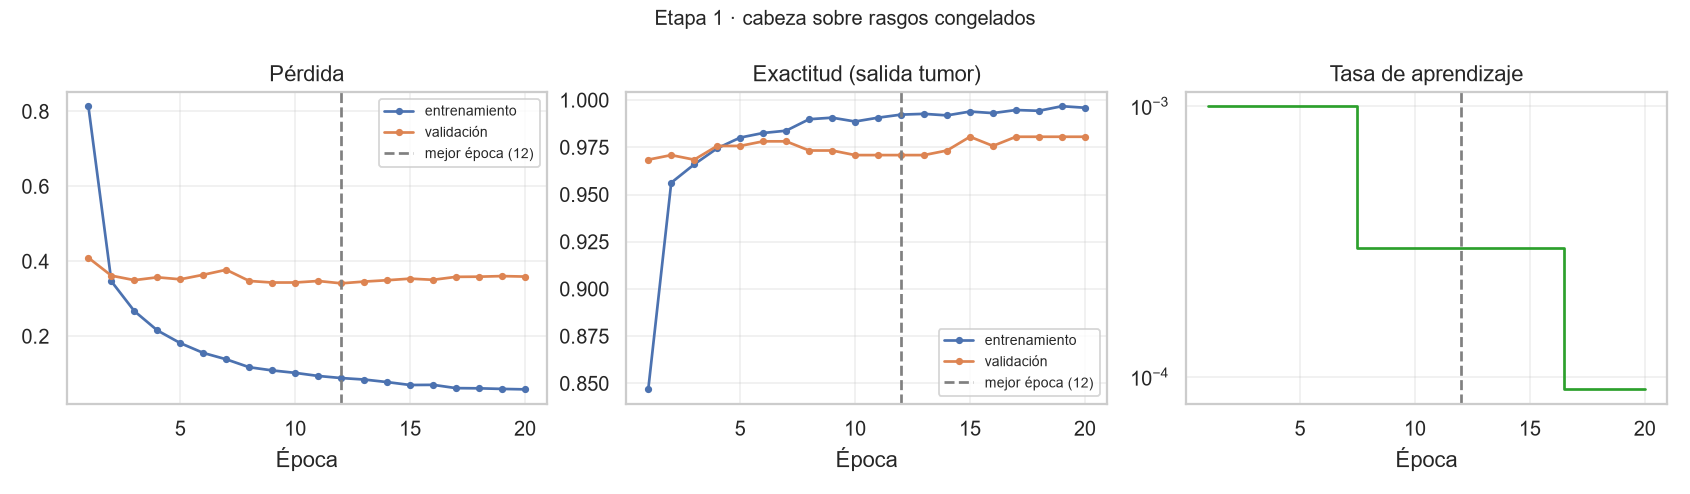

Cabeza → CONVERGIÓ (mejor época: 12 de 20 corridas)
   La pérdida de validación llegó a su mínimo en la época 12 (0.3411) y la detención temprana actuó en la época 20 de 60 tras 8 épocas sin mejorar. Se conservan los pesos de esa época. Es un mínimo de la pérdida de validación, no una garantía de mínimo global.
   Advertencias: 0
   Matiz: en la mejor época la pérdida de entrenamiento fue 0.26 veces la de validación (la advertencia de memorización salta por debajo de 0.25) y la exactitud de entrenamiento fue 0.992 (la advertencia salta desde 0.995). Quedó cerca de esos límites: el 'convergió' es sin advertencia, pero por poco.



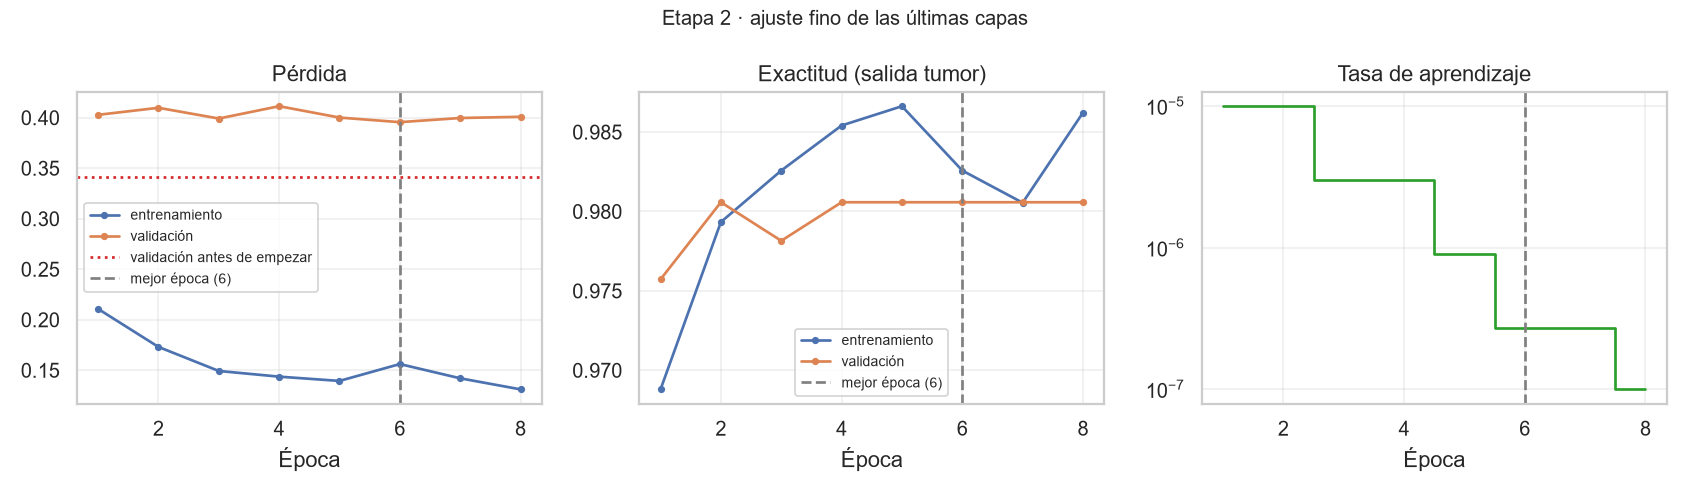

Ajuste fino → CONVERGIÓ (mejor época: 6 de 8 corridas)
   El entrenamiento no mejoró el modelo de partida: la pérdida de validación antes de empezar era 0.3411 y la mejor que se logró fue 0.3956 (época 6). Conviene quedarse con el modelo de partida. La pérdida de validación llegó a su mínimo en la época 6 (0.3956) y la pérdida de validación se aplanó antes de terminar las 8 épocas. Se conservan los pesos de esa época. Es un mínimo de la pérdida de validación, no una garantía de mínimo global.
   Advertencias: 1



In [8]:
curva_cabeza = graficar_curvas(hist_cabeza, diag_cabeza["mejor_epoca"], FIGURAS / "red_curvas_cabeza.png", "Etapa 1 · cabeza sobre rasgos congelados")
curva_ajuste = graficar_curvas(hist_ajuste, diag_ajuste["mejor_epoca"], FIGURAS / "red_curvas_ajuste_fino.png", "Etapa 2 · ajuste fino de las últimas capas")
for nombre, curva, diag in [("Cabeza", curva_cabeza, diag_cabeza), ("Ajuste fino", curva_ajuste, diag_ajuste)]:
    display(Imagen(filename=curva))
    print(f"{nombre} → {diag['etiqueta'].upper()} (mejor época: {diag['mejor_epoca']} de {diag['epocas_corridas']} corridas)")
    print("  ", diag["explicacion"])
    print("   Advertencias:", len(diag["advertencias"]))
    if diag["etiqueta"] == "convergió" and not diag["advertencias"]:
        from app.backend.ml import diagnostico as _dg
        _h = hist_cabeza if nombre == "Cabeza" else hist_ajuste
        _k = diag["mejor_epoca"] - 1
        _razon, _exa = _h["loss"][_k] / _h["val_loss"][_k], _h["accuracy"][_k]
        if _razon < _dg.RAZON_MEMORIZACION + 0.10 or _exa >= _dg.EXACTITUD_MEMORIZACION - 0.01:
            print(f"   Matiz: en la mejor época la pérdida de entrenamiento fue {_razon:.2f} veces la de validación (la advertencia de memorización "
                  f"salta por debajo de {_dg.RAZON_MEMORIZACION}) y la exactitud de entrenamiento fue {_exa:.3f} (la advertencia salta desde {_dg.EXACTITUD_MEMORIZACION}). "
                  "Quedó cerca de esos límites: el 'convergió' es sin advertencia, pero por poco.")
    print()

### 4.5 ¿Cabeza sola o modelo con ajuste fino?
Se comparan en la **misma validación** y con la **misma pérdida** (`val_loss`). Se exporta el que tenga menor pérdida de validación. Si el ajuste fino no mejora, se exporta la cabeza sola (dentro del modelo completo) y se dice tal cual. La prueba no interviene en esta decisión.

In [9]:
y_va = y_ent[i_va]
val_cabeza, val_ajuste = float(hist_ajuste["val_loss_inicial"]), float(min(hist_ajuste["val_loss"]))
comparacion = []
for nombre, p, perdida in [("cabeza sola", p_va_antes, val_cabeza), ("con ajuste fino", p_va_ajuste, val_ajuste)]:
    u = elegir_umbral(y_va, p, OBJETIVO)
    comparacion.append({"variante": nombre, "perdida_val": perdida, "umbral_sens_098": u, **metricas_binarias(y_va, p, u)})
comparacion = pd.DataFrame(comparacion)
display(comparacion[["variante", "perdida_val", "umbral_sens_098", "sensibilidad", "especificidad", "auc", "fn", "fp"]].round(4))

USAR_AJUSTE = val_ajuste < val_cabeza
if USAR_AJUSTE:
    modelo_final, ETAPA, p_va_final, diag_final = completo, "ajuste_fino", p_va_ajuste, diag_ajuste
    print(f"El ajuste fino MEJORÓ la pérdida de validación ({val_cabeza:.4f} → {val_ajuste:.4f}). Se exporta el modelo con ajuste fino.")
else:
    modelo_final, ETAPA, p_va_final, diag_final = red.construir_completo(cabeza=cabeza), "cabeza", p_va_antes, diag_cabeza
    print(f"El ajuste fino NO mejoró la pérdida de validación ({val_cabeza:.4f} → {val_ajuste:.4f}). Se exporta la cabeza sola (MobileNetV2 congelada).")

,variante,perdida_val,umbral_sens_098,sensibilidad,especificidad,auc,fn,fp
0,cabeza sola,0.3411,0.4319,0.9811,0.9286,0.9741,7,3
1,con ajuste fino,0.3956,0.6712,0.9811,0.9286,0.9777,7,3


El ajuste fino NO mejoró la pérdida de validación (0.3411 → 0.3956). Se exporta la cabeza sola (MobileNetV2 congelada).


## 5. Umbral de decisión
El umbral es el más alto con sensibilidad ≥ 0.98 (con un pequeño margen para que ninguna imagen quede justo encima). El valor que se guarda es el **punto medio** entre la probabilidad límite que da sensibilidad ≥ 0.98 y la siguiente probabilidad más baja. **Con qué datos se elige** depende de lo que se exporta.

**Nota de honestidad sobre esta regla:** se adoptó **después** de haber visto resultados de prueba de una división anterior de los datos (en la primera entrega el umbral salía de la validación apartada). Con la división actual el código **no usa la prueba** para elegir el umbral ni ninguna otra cosa, y la regla no se volvió a cambiar. La regla es:

- **Si se exporta la cabeza sola:** con las **predicciones fuera de pliegue** de la validación cruzada de la cabeza (todo el entrenamiento). Son la misma arquitectura y la misma receta de entrenamiento, cada predicción viene de un modelo que **no vio** esa imagen, y son varias veces más casos que la validación apartada. La validación apartada, en cambio, es pequeña y ya se usó para la detención temprana, así que un umbral elegido ahí sería optimista e inestable.
- **Si se exporta el modelo con ajuste fino:** con la **validación apartada**, porque del ajuste fino no existen predicciones fuera de pliegue (se entrenó una sola vez).

Limitación: las predicciones fuera de pliegue vienen de 5 modelos hermanos, no del modelo exportado; su calibración puede diferir un poco. La validación apartada se usa abajo como comprobación, y la prueba mide el resultado final.

Umbral elegido: 0.520507 · origen: predicciones fuera de pliegue de la validación cruzada de la cabeza (2880 imágenes de entrenamiento)
En los datos donde se eligió: {'vp': 2535, 'vn': 266, 'fp': 28, 'fn': 51, 'sensibilidad': 0.9803, 'especificidad': 0.9048, 'precision': 0.9891, 'f1': 0.9847, 'exactitud': 0.9726, 'auc': 0.9844}
Comprobación en la validación apartada del modelo exportado: {'vp': 361, 'vn': 39, 'fp': 3, 'fn': 9, 'sensibilidad': 0.9757, 'especificidad': 0.9286, 'precision': 0.9918, 'f1': 0.9837, 'exactitud': 0.9709, 'auc': 0.9741}
(Como referencia: el umbral que saldría solo de la validación apartada sería 0.431893)


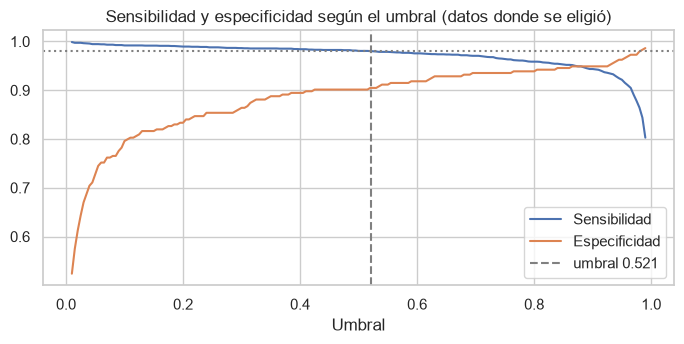

In [10]:
if USAR_AJUSTE:
    y_umbral, p_umbral = y_va, p_va_final
    ORIGEN_UMBRAL = f"validación apartada por grupos ({len(i_va)} imágenes) del modelo con ajuste fino"
else:
    y_umbral, p_umbral = y_ent, prob_oof
    ORIGEN_UMBRAL = f"predicciones fuera de pliegue de la validación cruzada de la cabeza ({len(y_ent)} imágenes de entrenamiento)"
UMBRAL = elegir_umbral(y_umbral, p_umbral, OBJETIVO)
m_umbral = metricas_binarias(y_umbral, p_umbral, UMBRAL)
m_val = metricas_binarias(y_va, p_va_final, UMBRAL)
print(f"Umbral elegido: {UMBRAL:.6f} · origen: {ORIGEN_UMBRAL}")
print("En los datos donde se eligió:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_umbral.items()})
print("Comprobación en la validación apartada del modelo exportado:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_val.items()})
print(f"(Como referencia: el umbral que saldría solo de la validación apartada sería {elegir_umbral(y_va, p_va_final, OBJETIVO):.6f})")

umbrales = np.linspace(0.01, 0.99, 197)
sens = [metricas_binarias(y_umbral, p_umbral, u)["sensibilidad"] for u in umbrales]
espe = [metricas_binarias(y_umbral, p_umbral, u)["especificidad"] for u in umbrales]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(umbrales, sens, label="Sensibilidad"); ax.plot(umbrales, espe, label="Especificidad")
ax.axvline(UMBRAL, ls="--", color="gray", label=f"umbral {UMBRAL:.3f}"); ax.axhline(OBJETIVO, ls=":", color="gray")
ax.set_xlabel("Umbral"); ax.set_title("Sensibilidad y especificidad según el umbral (datos donde se eligió)"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURAS / "red_umbral.png", dpi=130); plt.show()

## 6. Evaluación única en el conjunto de prueba
El modelo, el umbral y la decisión cabeza / ajuste fino ya están fijos. Ahora, y solo ahora, se usa la prueba.

Prueba (720 imágenes) · modelo exportado: cabeza · umbral 0.5205
  Sensibilidad  0.9675  (IC 95 % de Wilson: 0.9509 a 0.9787) · falsos negativos: 21
  Especificidad 0.8904  (IC 95 % de Wilson: 0.7984 a 0.9434) · falsos positivos: 8
  Precisión 0.9874 · F1 0.9774 · AUC 0.9825 · exactitud 0.9597
  Dato secundario · exactitud del tipo de tumor en los casos con tumor: 0.8779


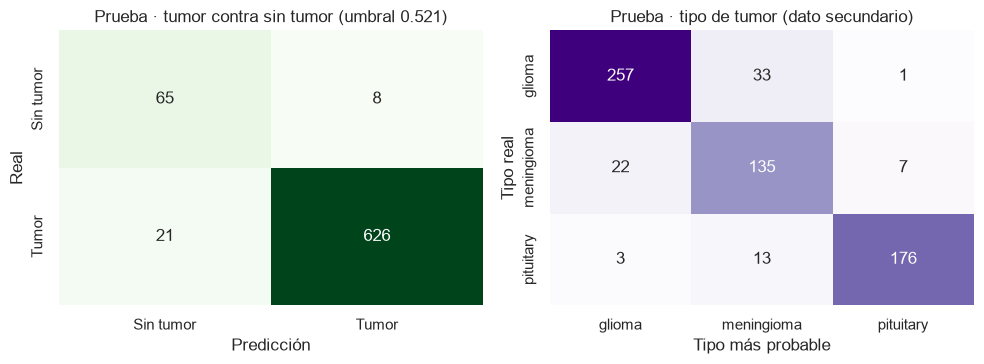

In [11]:
t0 = time.time()
p_pru, p_tipo_pru = entrenar.predecir_completo(modelo_final, img_pru)
tiempos["prediccion_prueba_s"] = time.time() - t0
m_pru = metricas_binarias(y_pru, p_pru, UMBRAL)
s_li, s_ls = wilson(m_pru["vp"], m_pru["vp"] + m_pru["fn"])
e_li, e_ls = wilson(m_pru["vn"], m_pru["vn"] + m_pru["fp"])
con_tumor = tipo_pru >= 0
exactitud_tipo = float((p_tipo_pru[con_tumor].argmax(1) == tipo_pru[con_tumor]).mean())

fila_prueba = {"modelo": NOMBRE_RED, "umbral": UMBRAL, "n": len(y_pru), **m_pru,
               "sensibilidad_ic95_inferior": s_li, "sensibilidad_ic95_superior": s_ls,
               "especificidad_ic95_inferior": e_li, "especificidad_ic95_superior": e_ls,
               "segundos_entrenamiento": tiempos["cabeza_s"] + tiempos["ajuste_fino_s"]}
prueba_resumen = agregar("prueba_resumen.csv", pd.DataFrame([fila_prueba]))
tipos_pred = [config.TIPOS_TUMOR[k] for k in p_tipo_pru.argmax(1)]
pred_prueba = agregar("predicciones_prueba.csv", pd.DataFrame({
    "ruta": man_pru.ruta, "modelo": NOMBRE_RED, "clase": man_pru.clase, "es_tumor": y_pru, "probabilidad_tumor": p_pru,
    "umbral": UMBRAL, "prediccion": (p_pru >= UMBRAL).astype(int), "tipo_probable": tipos_pred,
    "probabilidad_tipo": p_tipo_pru.max(1)}))

print(f"Prueba ({len(y_pru):,} imágenes) · modelo exportado: {ETAPA} · umbral {UMBRAL:.4f}")
print(f"  Sensibilidad  {m_pru['sensibilidad']:.4f}  (IC 95 % de Wilson: {s_li:.4f} a {s_ls:.4f}) · falsos negativos: {m_pru['fn']}")
print(f"  Especificidad {m_pru['especificidad']:.4f}  (IC 95 % de Wilson: {e_li:.4f} a {e_ls:.4f}) · falsos positivos: {m_pru['fp']}")
print(f"  Precisión {m_pru['precision']:.4f} · F1 {m_pru['f1']:.4f} · AUC {m_pru['auc']:.4f} · exactitud {m_pru['exactitud']:.4f}")
print(f"  Dato secundario · exactitud del tipo de tumor en los casos con tumor: {exactitud_tipo:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
cm = np.array([[m_pru["vn"], m_pru["fp"]], [m_pru["fn"], m_pru["vp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axs[0], xticklabels=["Sin tumor", "Tumor"], yticklabels=["Sin tumor", "Tumor"])
axs[0].set_title(f"Prueba · tumor contra sin tumor (umbral {UMBRAL:.3f})"); axs[0].set_xlabel("Predicción"); axs[0].set_ylabel("Real")
cm_tipo = pd.crosstab(pd.Series(man_pru.clase[con_tumor].to_numpy(), name="Tipo real"), pd.Series(np.array(tipos_pred)[con_tumor], name="Tipo más probable")).reindex(index=config.TIPOS_TUMOR, columns=config.TIPOS_TUMOR, fill_value=0)
sns.heatmap(cm_tipo, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axs[1]); axs[1].set_title("Prueba · tipo de tumor (dato secundario)")
plt.tight_layout(); plt.savefig(FIGURAS / "red_confusion_prueba.png", dpi=130); plt.show()

## 7. Tabla comparativa final de los 5 modelos
- **Validación cruzada:** media ± desviación estándar de los 5 pliegues, al umbral elegido con las predicciones fuera de pliegue (por eso la sensibilidad queda cerca de 0.98 en todos; lo que cambia es la especificidad y el AUC).
- **Prueba:** una sola evaluación por modelo, con el umbral ya fijado.
- **Red Keras:** la validación cruzada es de la **cabeza con rasgos congelados**; la columna de prueba es del modelo exportado. El ajuste fino se entrenó **una sola vez**.

In [12]:
cvr, prr = cv_resumen.set_index("modelo"), prueba_resumen.set_index("modelo")
ORDEN = [m for m in cvr.index if m != NOMBRE_RED] + [NOMBRE_RED]
filas = []
for m in ORDEN:
    c, p = cvr.loc[m], prr.loc[m]
    fila = {"modelo": m, "umbral_cv": c.umbral}
    for met in ["sensibilidad", "especificidad", "precision", "f1", "auc"]:
        fila[f"cv_{met}_media"], fila[f"cv_{met}_std"] = c[f"{met}_media"], c[f"{met}_std"]
    fila["umbral_prueba"] = p.umbral
    for met in ["sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud"]:
        fila[f"prueba_{met}"] = p[met]
    for col in ["sensibilidad_ic95_inferior", "sensibilidad_ic95_superior", "especificidad_ic95_inferior", "especificidad_ic95_superior"]:
        fila[f"prueba_{col}"] = p[col]
    fila.update({"prueba_vp": int(p.vp), "prueba_vn": int(p.vn), "prueba_fp": int(p.fp), "prueba_fn": int(p.fn), "nota": c.nota})
    if m == NOMBRE_RED:
        fila["nota"] = (f"{NOTA_RED}. Prueba: modelo exportado = "
                        + ("con ajuste fino" if USAR_AJUSTE else "cabeza sola (el ajuste fino no mejoró la validación)")
                        + "; su umbral se eligió con: " + ORIGEN_UMBRAL)
    filas.append(fila)
tabla = pd.DataFrame(filas)
tabla.to_csv(config.RESULTADOS / "tabla_comparativa.csv", index=False, encoding="utf-8")

vista = pd.DataFrame({"Modelo": tabla.modelo})
for met, nombre in [("sensibilidad", "Sensibilidad"), ("especificidad", "Especificidad"), ("precision", "Precisión"), ("f1", "F1"), ("auc", "AUC")]:
    vista[f"CV {nombre}"] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(tabla[f"cv_{met}_media"], tabla[f"cv_{met}_std"])]
vista["Umbral"] = [f"{u:.4f}" for u in tabla.umbral_prueba]
vista["Prueba Sensibilidad (IC 95 %)"] = [f"{s:.4f} ({a:.3f} a {b:.3f})" for s, a, b in zip(tabla.prueba_sensibilidad, tabla.prueba_sensibilidad_ic95_inferior, tabla.prueba_sensibilidad_ic95_superior)]
vista["Prueba Especificidad (IC 95 %)"] = [f"{s:.4f} ({a:.3f} a {b:.3f})" for s, a, b in zip(tabla.prueba_especificidad, tabla.prueba_especificidad_ic95_inferior, tabla.prueba_especificidad_ic95_superior)]
for met, nombre in [("precision", "Precisión"), ("f1", "F1"), ("auc", "AUC")]:
    vista[f"Prueba {nombre}"] = [f"{v:.4f}" for v in tabla[f"prueba_{met}"]]
vista["FN"], vista["FP"] = tabla.prueba_fn, tabla.prueba_fp


def a_markdown(t):
    lineas = ["| " + " | ".join(t.columns) + " |", "|" + "|".join(["---"] * len(t.columns)) + "|"]
    lineas += ["| " + " | ".join(str(v) for v in fila) + " |" for fila in t.itertuples(index=False)]
    return "\n".join(lineas)


notas_md = f"""
**Notas**
- Validación cruzada (CV): 5 pliegues estratificados **por grupos de similitud** sobre {len(y_ent):,} imágenes de entrenamiento; media ± desviación estándar entre pliegues. El umbral de cada modelo es el punto medio entre la probabilidad límite con sensibilidad ≥ {OBJETIVO} en las predicciones fuera de pliegue y la siguiente probabilidad inferior; por eso la sensibilidad de CV queda cerca de {OBJETIVO} por construcción.
- Prueba: {len(y_pru):,} imágenes; una sola evaluación por modelo con esta división, y el código no las usa para elegir nada. Intervalos de confianza de Wilson al 95 %. FN = falsos negativos (tumores no detectados); FP = falsos positivos.
- **Advertencia sobre la especificidad:** en la prueba solo hay **{int((y_pru == 0).sum())} imágenes "sin tumor"** (y {int((y_ent == 0).sum())} en entrenamiento). La especificidad de prueba se mide con esas pocas imágenes: cada falso positivo la mueve {100 / max(1, int((y_pru == 0).sum())):.1f} puntos porcentuales y su intervalo de confianza es ancho. Las diferencias de especificidad entre modelos deben leerse con esa cautela.
- **Límite de la división:** las copias y las imágenes con correlación mayor de 0.95 quedan del mismo lado (grupos de similitud), pero el dataset no trae identificador de paciente: puede quedar fuga por estudio (cortes vecinos) y las métricas pueden estar algo optimistas.
- {NOMBRE_RED}: el K-fold se hizo sobre la **cabeza con los rasgos de MobileNetV2 congelados**; el umbral de CV de la cabeza fue {umbral_cv:.4f}. El **ajuste fino se entrenó una sola vez** (decisión del usuario por tiempo de cómputo), con {len(i_va)} imágenes del entrenamiento apartadas por grupos como validación. Modelo evaluado en prueba y exportado: **{"con ajuste fino" if USAR_AJUSTE else "cabeza sola; el ajuste fino no mejoró la pérdida de validación"}**, con umbral {UMBRAL:.4f} elegido con: {ORIGEN_UMBRAL}.
- Proyecto académico de apoyo a la decisión. No sustituye el diagnóstico de un médico especialista.
"""
texto_md = "# Tabla comparativa de modelos · tumor contra sin tumor\n\n" + a_markdown(vista) + "\n" + notas_md
(config.RESULTADOS / "tabla_comparativa.md").write_text(texto_md, encoding="utf-8")
display(Markdown(texto_md))

# Tabla comparativa de modelos · tumor contra sin tumor

| Modelo | CV Sensibilidad | CV Especificidad | CV Precisión | CV F1 | CV AUC | Umbral | Prueba Sensibilidad (IC 95 %) | Prueba Especificidad (IC 95 %) | Prueba Precisión | Prueba F1 | Prueba AUC | FN | FP |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Logística (rasgos básicos) | 0.9803 ± 0.0034 | 0.2689 ± 0.0651 | 0.9219 ± 0.0067 | 0.9502 ± 0.0038 | 0.9040 ± 0.0462 | 0.0225 | 0.9768 (0.962 a 0.986) | 0.3014 (0.208 a 0.414) | 0.9253 | 0.9504 | 0.9389 | 15 | 51 |
| Logística (MobileNetV2) | 0.9803 ± 0.0079 | 0.8843 ± 0.0187 | 0.9868 ± 0.0021 | 0.9835 ± 0.0038 | 0.9868 ± 0.0115 | 0.6276 | 0.9784 (0.964 a 0.987) | 0.8630 (0.766 a 0.924) | 0.9844 | 0.9814 | 0.9813 | 14 | 10 |
| Random Forest (MobileNetV2) | 0.9803 ± 0.0060 | 0.7822 ± 0.0359 | 0.9754 ± 0.0037 | 0.9778 ± 0.0016 | 0.9855 ± 0.0057 | 0.6367 | 0.9830 (0.970 a 0.990) | 0.7945 (0.688 a 0.871) | 0.9770 | 0.9800 | 0.9870 | 11 | 15 |
| SVM RBF (MobileNetV2) | 0.9803 ± 0.0088 | 0.9150 ± 0.0205 | 0.9902 ± 0.0024 | 0.9852 ± 0.0047 | 0.9913 ± 0.0033 | 0.7493 | 0.9784 (0.964 a 0.987) | 0.8630 (0.766 a 0.924) | 0.9844 | 0.9814 | 0.9782 | 14 | 10 |
| Red Keras (MobileNetV2) | 0.9803 ± 0.0075 | 0.9048 ± 0.0307 | 0.9891 ± 0.0035 | 0.9846 ± 0.0038 | 0.9856 ± 0.0074 | 0.5205 | 0.9675 (0.951 a 0.979) | 0.8904 (0.798 a 0.943) | 0.9874 | 0.9774 | 0.9825 | 21 | 8 |

**Notas**
- Validación cruzada (CV): 5 pliegues estratificados **por grupos de similitud** sobre 2,880 imágenes de entrenamiento; media ± desviación estándar entre pliegues. El umbral de cada modelo es el punto medio entre la probabilidad límite con sensibilidad ≥ 0.98 en las predicciones fuera de pliegue y la siguiente probabilidad inferior; por eso la sensibilidad de CV queda cerca de 0.98 por construcción.
- Prueba: 720 imágenes; una sola evaluación por modelo con esta división, y el código no las usa para elegir nada. Intervalos de confianza de Wilson al 95 %. FN = falsos negativos (tumores no detectados); FP = falsos positivos.
- **Advertencia sobre la especificidad:** en la prueba solo hay **73 imágenes "sin tumor"** (y 294 en entrenamiento). La especificidad de prueba se mide con esas pocas imágenes: cada falso positivo la mueve 1.4 puntos porcentuales y su intervalo de confianza es ancho. Las diferencias de especificidad entre modelos deben leerse con esa cautela.
- **Límite de la división:** las copias y las imágenes con correlación mayor de 0.95 quedan del mismo lado (grupos de similitud), pero el dataset no trae identificador de paciente: puede quedar fuga por estudio (cortes vecinos) y las métricas pueden estar algo optimistas.
- Red Keras (MobileNetV2): el K-fold se hizo sobre la **cabeza con los rasgos de MobileNetV2 congelados**; el umbral de CV de la cabeza fue 0.5205. El **ajuste fino se entrenó una sola vez** (decisión del usuario por tiempo de cómputo), con 412 imágenes del entrenamiento apartadas por grupos como validación. Modelo evaluado en prueba y exportado: **cabeza sola; el ajuste fino no mejoró la pérdida de validación**, con umbral 0.5205 elegido con: predicciones fuera de pliegue de la validación cruzada de la cabeza (2880 imágenes de entrenamiento).
- Proyecto académico de apoyo a la decisión. No sustituye el diagnóstico de un médico especialista.


### 7.1 Prueba de McNemar: ¿la red es distinta del mejor modelo clásico?
Los dos modelos se evaluaron sobre las mismas imágenes de prueba, cada uno con su umbral. McNemar solo mira los casos en que uno acierta y el otro falla.
- H0: los dos modelos se equivocan con la misma frecuencia.
- El "mejor clásico" es el que eligió la validación cruzada en el notebook 03 (no se eligió con la prueba).

Se hace **dos veces**: con todas las imágenes de prueba (aciertos y errores de cualquier tipo) y **solo con los casos de tumor**. La segunda compara directamente la **sensibilidad**, que es la métrica principal del proyecto: ahí solo cuentan los tumores que un modelo detecta y el otro deja pasar. Los valores p no están corregidos por comparaciones múltiples.

In [13]:
info_clasicos = json.loads((config.RESULTADOS / "modelos_clasicos" / "info.json").read_text(encoding="utf-8"))
MEJOR_CLASICO = info_clasicos["_mejor_por_validacion_cruzada"]
ancho = pred_prueba.assign(acierta=pred_prueba.prediccion == pred_prueba.es_tumor).pivot(index="ruta", columns="modelo", values="acierta").loc[man_pru.ruta]
filas_mc = []
for otro in [m for m in ORDEN if m != NOMBRE_RED]:
    b, c, p, metodo = mcnemar(ancho[NOMBRE_RED].to_numpy(), ancho[otro].to_numpy())
    filas_mc.append({"modelo_a": NOMBRE_RED, "modelo_b": otro, "a_acierta_b_falla": b, "a_falla_b_acierta": c, "p_valor": p,
                     "metodo": metodo, "diferencia_significativa": p < 0.05, "es_mejor_clasico_cv": otro == MEJOR_CLASICO})
tabla_mc = pd.DataFrame(filas_mc)
tabla_mc.insert(2, "subconjunto", "todas las imágenes de prueba")
es_tumor_pru = y_pru == 1
filas_tumor = []
for otro in [m for m in ORDEN if m != NOMBRE_RED]:
    b, c, p, metodo = mcnemar(ancho[NOMBRE_RED].to_numpy()[es_tumor_pru], ancho[otro].to_numpy()[es_tumor_pru])
    filas_tumor.append({"modelo_a": NOMBRE_RED, "modelo_b": otro, "subconjunto": "solo casos con tumor (sensibilidad)",
                        "a_acierta_b_falla": b, "a_falla_b_acierta": c, "p_valor": p, "metodo": metodo,
                        "diferencia_significativa": p < 0.05, "es_mejor_clasico_cv": otro == MEJOR_CLASICO})
tabla_mc = pd.concat([tabla_mc, pd.DataFrame(filas_tumor)], ignore_index=True)
tabla_mc.to_csv(config.RESULTADOS / "mcnemar.csv", index=False, encoding="utf-8")
display(tabla_mc)

mc = tabla_mc[(tabla_mc.modelo_b == MEJOR_CLASICO) & (tabla_mc.subconjunto == "todas las imágenes de prueba")].iloc[0]
mc_t = tabla_mc[(tabla_mc.modelo_b == MEJOR_CLASICO) & (tabla_mc.subconjunto != "todas las imágenes de prueba")].iloc[0]
red_p, cla_p = prr.loc[NOMBRE_RED], prr.loc[MEJOR_CLASICO]
print(f"Mejor clásico por validación cruzada: {MEJOR_CLASICO}")
print(f"  Red:     sensibilidad {red_p.sensibilidad:.4f} · especificidad {red_p.especificidad:.4f} · FN {int(red_p.fn)} · FP {int(red_p.fp)} · AUC {red_p.auc:.4f}")
print(f"  Clásico: sensibilidad {cla_p.sensibilidad:.4f} · especificidad {cla_p.especificidad:.4f} · FN {int(cla_p.fn)} · FP {int(cla_p.fp)} · AUC {cla_p.auc:.4f}")
print(f"  McNemar ({mc.metodo}): la red acierta y el clásico falla en {mc.a_acierta_b_falla}; la red falla y el clásico acierta en {mc.a_falla_b_acierta}; p = {mc.p_valor:.4g}")
errores_red, errores_cla = int(red_p.fn + red_p.fp), int(cla_p.fn + cla_p.fp)
conteo = (f"La red cometió {errores_red} errores ({int(red_p.fn)} falsos negativos y {int(red_p.fp)} falsos positivos) y "
          f"{MEJOR_CLASICO} cometió {errores_cla} ({int(cla_p.fn)} falsos negativos y {int(cla_p.fp)} falsos positivos), de {len(y_pru):,} imágenes.")
if mc.p_valor >= 0.05:
    conclusion = (f"No se detecta una diferencia significativa entre la red y {MEJOR_CLASICO} en la prueba (McNemar, p = {mc.p_valor:.3f}). {conteo} "
                  "Eso no demuestra que sean iguales: con esta cantidad de imágenes la prueba solo detecta diferencias grandes. "
                  "Lo que sí se puede decir es que la red no mostró ventaja sobre ese modelo clásico.")
elif errores_red < errores_cla:
    conclusion = f"La red comete significativamente menos errores que {MEJOR_CLASICO} en la prueba (McNemar, p = {mc.p_valor:.3f}). {conteo}"
else:
    conclusion = f"El modelo clásico {MEJOR_CLASICO} comete significativamente MENOS errores que la red en la prueba (McNemar, p = {mc.p_valor:.3f}). {conteo} Gana el modelo clásico."
n_tumor = int(es_tumor_pru.sum())
detalle_t = (f"Solo en los {n_tumor} casos con tumor: la red detecta {mc_t.a_acierta_b_falla} tumores que {MEJOR_CLASICO} deja pasar y deja pasar "
             f"{mc_t.a_falla_b_acierta} que {MEJOR_CLASICO} detecta (McNemar, {mc_t.metodo}, p = {mc_t.p_valor:.4g}, sin corregir por comparaciones múltiples).")
if mc_t.p_valor < 0.05 and mc_t.a_falla_b_acierta > mc_t.a_acierta_b_falla:
    conclusion_sens = (f"En la métrica principal del proyecto (sensibilidad), {MEJOR_CLASICO} fue MEJOR que la red en esta prueba. {detalle_t} "
                       f"La diferencia global no es significativa porque la red tuvo {int(cla_p.fp - red_p.fp)} falsos positivos menos.")
elif mc_t.p_valor < 0.05:
    conclusion_sens = f"En la métrica principal del proyecto (sensibilidad), la red fue mejor que {MEJOR_CLASICO} en esta prueba. {detalle_t}"
else:
    conclusion_sens = f"En sensibilidad no se detecta una diferencia significativa entre la red y {MEJOR_CLASICO}. {detalle_t}"
conclusion = conclusion + "\n" + conclusion_sens
nota_mc = (f"- **McNemar, {NOMBRE_RED} contra {MEJOR_CLASICO} (mejor clásico por validación cruzada):** con todas las imágenes de prueba, "
           f"la red acierta y el clásico falla en {mc.a_acierta_b_falla}, y al revés en {mc.a_falla_b_acierta} (p = {mc.p_valor:.4g}). {conclusion_sens}\n")
texto_md = texto_md.rstrip("\n") + "\n" + nota_mc
(config.RESULTADOS / "tabla_comparativa.md").write_text(texto_md, encoding="utf-8")
menos_fn = prr.fn.astype(int).idxmin()
print("\nConclusión:", conclusion)
print(f"Modelo con menos falsos negativos en prueba: {menos_fn} ({int(prr.loc[menos_fn, 'fn'])}). "
      f"Modelo con mayor especificidad en prueba: {prr.especificidad.idxmax()} ({prr.especificidad.max():.4f}).")
alcanzan = [m for m in ORDEN if prr.loc[m, "sensibilidad"] >= OBJETIVO]
print(f"Modelos que alcanzan sensibilidad ≥ {OBJETIVO} en prueba: {alcanzan if alcanzan else 'ninguno'}")
n_sin = int((y_pru == 0).sum())
print(f"ADVERTENCIA: la especificidad de prueba se mide con solo {n_sin} imágenes 'sin tumor'; su intervalo de confianza es ancho "
      f"(red: {red_p.especificidad_ic95_inferior:.3f} a {red_p.especificidad_ic95_superior:.3f}; {MEJOR_CLASICO}: {cla_p.especificidad_ic95_inferior:.3f} a {cla_p.especificidad_ic95_superior:.3f}). "
      "Con tan pocas imágenes no se puede afirmar qué modelo tiene mejor especificidad.")

,modelo_a,modelo_b,subconjunto,a_acierta_b_falla,a_falla_b_acierta,p_valor,metodo,diferencia_significativa,es_mejor_clasico_cv
0,Red Keras (MobileNetV2),Logística (rasgos básicos),todas las imágenes de prueba,53,16,0.000015,ji cuadrada con corrección,True,False
1,Red Keras (MobileNetV2),Logística (MobileNetV2),todas las imágenes de prueba,4,9,0.266846,exacta (binomial),False,False
2,Red Keras (MobileNetV2),Random Forest (MobileNetV2),todas las imágenes de prueba,8,11,0.647606,exacta (binomial),False,False
3,Red Keras (MobileNetV2),SVM RBF (MobileNetV2),todas las imágenes de prueba,3,8,0.226562,exacta (binomial),False,True
4,Red Keras (MobileNetV2),Logística (rasgos básicos),solo casos con tumor (sensibilidad),8,14,0.286279,exacta (binomial),False,False
5,Red Keras (MobileNetV2),Logística (MobileNetV2),solo casos con tumor (sensibilidad),1,8,0.039062,exacta (binomial),True,False
6,Red Keras (MobileNetV2),Random Forest (MobileNetV2),solo casos con tumor (sensibilidad),1,11,0.006348,exacta (binomial),True,False
7,Red Keras (MobileNetV2),SVM RBF (MobileNetV2),solo casos con tumor (sensibilidad),0,7,0.015625,exacta (binomial),True,True


Mejor clásico por validación cruzada: SVM RBF (MobileNetV2)
  Red:     sensibilidad 0.9675 · especificidad 0.8904 · FN 21 · FP 8 · AUC 0.9825
  Clásico: sensibilidad 0.9784 · especificidad 0.8630 · FN 14 · FP 10 · AUC 0.9782
  McNemar (exacta (binomial)): la red acierta y el clásico falla en 3; la red falla y el clásico acierta en 8; p = 0.2266

Conclusión: No se detecta una diferencia significativa entre la red y SVM RBF (MobileNetV2) en la prueba (McNemar, p = 0.227). La red cometió 29 errores (21 falsos negativos y 8 falsos positivos) y SVM RBF (MobileNetV2) cometió 24 (14 falsos negativos y 10 falsos positivos), de 720 imágenes. Eso no demuestra que sean iguales: con esta cantidad de imágenes la prueba solo detecta diferencias grandes. Lo que sí se puede decir es que la red no mostró ventaja sobre ese modelo clásico.
En la métrica principal del proyecto (sensibilidad), SVM RBF (MobileNetV2) fue MEJOR que la red en esta prueba. Solo en los 647 casos con tumor: la red detecta 0 tumor

## 8. Grad-CAM: zona que más influyó
El mapa de calor marca la **zona de la imagen que más influyó** en la respuesta que dio el modelo: hacia "tumor" cuando respondió tumor, y hacia "sin tumor" cuando respondió sin tumor. **No es la ubicación del tumor** ni una segmentación: es una ayuda para revisar si el modelo mira el cerebro o algo irrelevante (bordes, texto, fondo).

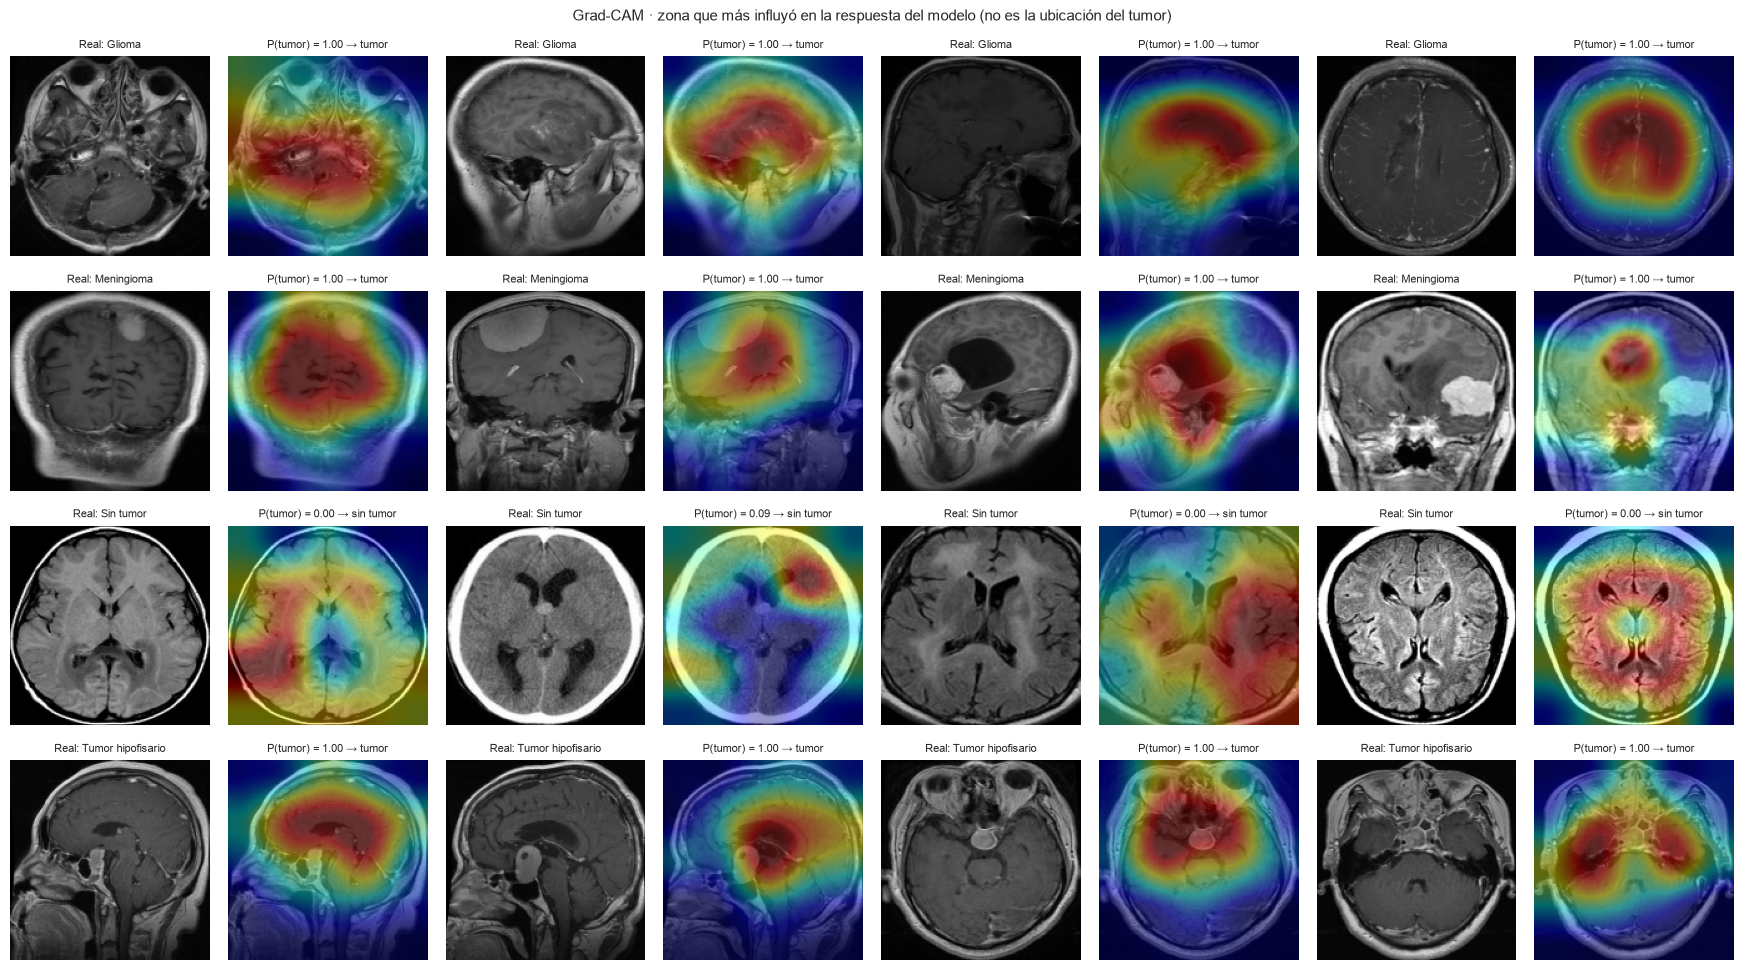

In [14]:
rng = np.random.default_rng(config.SEMILLA)
POR_CLASE = 4
fig, axs = plt.subplots(len(config.CLASES), POR_CLASE * 2, figsize=(2.2 * POR_CLASE * 2, 2.5 * len(config.CLASES)))
for fila, clase in zip(axs, config.CLASES):
    elegidos = rng.choice(np.where(man_pru.clase.to_numpy() == clase)[0], POR_CLASE, replace=False)
    for j, i in enumerate(elegidos):
        mapa = mapa_gradcam(modelo_final, img_pru[i], hacia_tumor=bool(p_pru[i] >= UMBRAL))
        fila[2 * j].imshow(img_pru[i]); fila[2 * j].set_title(f"Real: {config.NOMBRES_ES[clase]}", fontsize=8)
        fila[2 * j + 1].imshow(superponer(img_pru[i], mapa))
        fila[2 * j + 1].set_title(f"P(tumor) = {p_pru[i]:.2f} → {'tumor' if p_pru[i] >= UMBRAL else 'sin tumor'}", fontsize=8)
    for ax in fila:
        ax.axis("off")
fig.suptitle("Grad-CAM · zona que más influyó en la respuesta del modelo (no es la ubicación del tumor)", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURAS / "red_gradcam.png", dpi=130); plt.show()

## 9. Exportación del modelo `v001`
- `modelo.keras`: modelo completo (imagen RGB de 160 × 160 con valores 0 a 255 → probabilidad de tumor y tipo). Se guarda sin optimizador.
- `info.json`: umbral, capa de Grad-CAM, clases, métricas, diagnóstico, versiones y semilla.
- `validacion.npz`: `y` y `prob` son las etiquetas y probabilidades **con las que se eligió el umbral** (para el control deslizante de umbral de la aplicación); `y_val` y `prob_val` son las de la validación apartada del modelo exportado.
- Curvas de entrenamiento en PNG.

In [15]:
entrenar.exportar_limpio(modelo_final, CARPETA_VERSION / "modelo.keras")
rutas_ent = man_ent.ruta.to_numpy().astype(str)
np.savez_compressed(CARPETA_VERSION / "validacion.npz", y=np.asarray(y_umbral).astype(np.int8), prob=np.asarray(p_umbral).astype(np.float64),
                    rutas=(rutas_ent[i_va] if USAR_AJUSTE else rutas_ent), origen=np.array(ORIGEN_UMBRAL),
                    y_val=y_va.astype(np.int8), prob_val=p_va_final.astype(np.float64), rutas_val=rutas_ent[i_va],
                    y_oof=y_ent.astype(np.int8), prob_oof_cabeza=prob_oof.astype(np.float64))
shutil.copy(curva_cabeza, CARPETA_VERSION / "curvas_cabeza.png")
shutil.copy(curva_ajuste, CARPETA_VERSION / "curvas_ajuste_fino.png")
shutil.copy(FIGURAS / "red_gradcam.png", CARPETA_VERSION / "gradcam_ejemplos.png")


def limpio(d):
    return {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in d.items()}


# Comprobación: predecir imagen por imagen (como la app) da la misma sensibilidad que en lote
uno_a_uno = np.array([float(np.asarray(modelo_final(img_ent[i][None].astype(np.float32), training=False)["tumor"]).ravel()[0]) for i in i_va])
m_uno = metricas_binarias(y_va, uno_a_uno, UMBRAL)
print(f"Validación apartada, en lote: FN {m_val['fn']} · FP {m_val['fp']}  |  imagen por imagen: FN {m_uno['fn']} · FP {m_uno['fp']}")
assert (m_uno["fn"], m_uno["fp"]) == (m_val["fn"], m_val["fp"]), "La predicción imagen por imagen no coincide con la de lote."


info = {
    "version": VERSION,
    "nombre": NOMBRE_RED,
    "tipo": "red_keras",
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "archivo_modelo": "modelo.keras",
    "etapa_exportada": ETAPA,
    "descripcion": ("MobileNetV2 con ajuste fino de las últimas capas + cabeza densa" if USAR_AJUSTE
                    else "MobileNetV2 congelada + cabeza densa (el ajuste fino no mejoró la validación)"),
    "entrada": "Imagen RGB uint8 de 160x160 con valores de 0 a 255 (recorte del cerebro + INTER_AREA); la normalización está dentro del modelo",
    "umbral": UMBRAL,
    "sensibilidad_objetivo": OBJETIVO,
    "origen_umbral": ORIGEN_UMBRAL,
    "metricas_umbral": {"n": int(len(y_umbral)), "umbral": UMBRAL, **m_umbral},
    "capa_gradcam": red.NOMBRE_CAPA_GRADCAM,
    "tam": config.TAM,
    "clases": config.CLASES,
    "tipos": config.TIPOS_TUMOR,
    "metricas_cv": {
        "nota": NOTA_RED, "pliegues": config.N_PLIEGUES, "umbral": umbral_cv,
        **{f"{m}_media": float(fila_cv[f"{m}_media"]) for m in METRICAS},
        **{f"{m}_std": float(fila_cv[f"{m}_std"]) for m in METRICAS},
        "por_pliegue": por_pliegue.drop(columns="modelo").to_dict(orient="records"),
    },
    "metricas_validacion": {"n": int(len(i_va)), "umbral": UMBRAL, **m_val},
    "metricas_prueba": {"n": int(len(y_pru)), "umbral": UMBRAL, **m_pru,
                        "sensibilidad_ic95": [s_li, s_ls], "especificidad_ic95": [e_li, e_ls],
                        "exactitud_tipo": exactitud_tipo},
    "mejor_epoca": int(diag_final["mejor_epoca"]),
    "diagnostico": diag_final["etiqueta"],
    "explicacion_diagnostico": diag_final["explicacion"],
    "advertencias_diagnostico": diag_final["advertencias"],
    "diagnostico_etapas": {"cabeza": limpio(diag_cabeza), "ajuste_fino": limpio(diag_ajuste)},
    "comparacion_validacion": {"perdida_val_cabeza": val_cabeza, "perdida_val_ajuste_fino": val_ajuste, "se_uso_ajuste_fino": bool(USAR_AJUSTE)},
    "entrenamiento": {
        "perdida_vigilada": "val_loss (pérdida total de validación = tumor ponderada por clase + 0.5 * tipo)",
        "n_entrenamiento": int(len(i_tr)), "n_validacion": int(len(i_va)), "n_prueba": int(len(y_pru)),
        "pesos_clase": {str(k): float(v) for k, v in red.pesos_clase(y_ent[i_tr]).items()},
        "cabeza": {"epocas_max": EPOCAS_CABEZA, "paciencia": PACIENCIA_CABEZA, "tasa": TASA_CABEZA, "lote": LOTE_CABEZA,
                   "epocas_corridas": len(hist_cabeza["loss"])},
        "ajuste_fino": {"epocas_max": EPOCAS_AJUSTE, "paciencia": PACIENCIA_AJUSTE, "tasa": TASA_AJUSTE, "lote": LOTE_AJUSTE,
                        "capas": CAPAS_AJUSTE, "capas_descongeladas": int(hist_ajuste["capas_descongeladas"]),
                        "epocas_corridas": len(hist_ajuste["loss"]), "veces_entrenado": 1},
        "segundos": {k: round(float(v), 1) for k, v in tiempos.items()},
    },
    "versiones": config.versiones(),
    "semilla": config.SEMILLA,
    "aviso": config.AVISO,
}
(CARPETA_VERSION / "info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print("Exportado en", CARPETA_VERSION)
for f in sorted(CARPETA_VERSION.iterdir()):
    print(f"   {f.name}  ({f.stat().st_size / 1e6:.2f} MB)")

Validación apartada, en lote: FN 9 · FP 3  |  imagen por imagen: FN 9 · FP 3
Exportado en C:\proyectos\tumores-cerebrales\app\modelos\v001
   curvas_ajuste_fino.png  (0.08 MB)
   curvas_cabeza.png  (0.07 MB)
   gradcam_ejemplos.png  (2.41 MB)
   info.json  (0.01 MB)
   modelo.keras  (10.95 MB)
   validacion.npz  (0.04 MB)


### Comprobación: el modelo exportado da lo mismo que el evaluado
Se carga `v001` con `inferencia.cargar_modelo` y se predicen imágenes de prueba **desde el archivo original**, por el mismo camino que usará la aplicación.

In [16]:
modelo_app, info_app = inferencia.cargar_modelo(CARPETA_VERSION)
muestra = rng.choice(len(man_pru), 12, replace=False)
diferencias = []
for i in muestra:
    r = inferencia.predecir(modelo_app, info_app, leer_imagen(config.RAIZ / man_pru.ruta[i]), con_gradcam=(i == muestra[0]))
    diferencias.append(abs(r["probabilidad_tumor"] - p_pru[i]))
    assert r["hay_tumor"] == bool(p_pru[i] >= UMBRAL)
print(f"Diferencia máxima entre la app y la evaluación en {len(muestra)} imágenes: {max(diferencias):.2e}")
assert max(diferencias) < 1e-4
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items() if k not in ("gradcam", "imagen_preparada", "gradcam_superpuesto")})
print(f"\nNotebook terminado en {(time.time() - INICIO) / 60:.1f} min · tiempos (s): { {k: round(v) for k, v in tiempos.items()} }")

Diferencia máxima entre la app y la evaluación en 12 imágenes: 4.62e-07
{'probabilidad_tumor': 0.9998, 'umbral': 0.5205, 'hay_tumor': True, 'tipo_probable': 'meningioma', 'probabilidad_tipo': 0.587, 'probabilidades_tipo': {'glioma': 0.4128262400627136, 'meningioma': 0.5870428681373596, 'pituitary': 0.00013083632802590728}, 'aviso': 'Resultado de apoyo. No sustituye el diagnóstico de un médico especialista.'}

Notebook terminado en 4.8 min · tiempos (s): {'kfold_cabeza_s': 29, 'cabeza_s': 6, 'ajuste_fino_s': 153, 'prediccion_prueba_s': 5}
